# Guía 4 — Anexo técnico integral

**Universidad de los Andes · Maestría en Inteligencia Analítica de Datos**  
**Gerencia de Proyectos de Analytics · Grupo 18**  
Raúl Monsalve Tapias · Víctor Osorio Gaviria · Felipe Ardila Acosta · Nicolás Segura Parra

Este notebook reúne los **Anexos Técnicos 1, 2 y 3** en el orden del informe. Se conservan los análisis y sus salidas de origen. Las únicas adaptaciones funcionales son las rutas de entrada/salida, la carga compartida de fuentes y la verificación del CSV auditado.

**Archivos de entrada requeridos**, en la misma carpeta del notebook o en `/content` de Colab:
- `Tarifas_aplicadas_de_Gas_Natural_20261016.xlsx` **o** `CREG_original_extraido.csv`
- `Tarifas_de_gas_natural_para_hogares_-_EPM_20261016.csv`

Los archivos auditados y las tablas derivadas se guardan en `salidas_guia4/`. **Las salidas incrustadas proceden de las ejecuciones originales; el notebook integral aún debe ejecutarse de principio a fin con las fuentes originales.**

# Anexo Técnico 1 — Características de calidad de los datos

## Anexo técnico
Características de calidad de los datos (CREG y EPM)

Este notebook genera las cifras usadas en el informe. Cada sección corresponde a un bloque del documento

In [16]:
import numpy as np
import pandas as pd
from pathlib import Path

BASE = Path.cwd()
OUT = BASE / 'salidas_guia4'
OUT.mkdir(exist_ok=True)
CREG_XLSX = BASE / 'Tarifas_aplicadas_de_Gas_Natural_20261016.xlsx'
CREG_CSV = BASE / 'CREG_original_extraido.csv'
EPM_CSV = BASE / 'Tarifas_de_gas_natural_para_hogares_-_EPM_20261016.csv'
assert CREG_CSV.exists() or CREG_XLSX.exists(), 'Falta la fuente CREG (CSV o XLSX)'
assert EPM_CSV.exists(), 'Falta la fuente EPM'
raw_c = (pd.read_csv(CREG_CSV, dtype=str, encoding='utf-8-sig', low_memory=False)
         if CREG_CSV.exists() else pd.read_excel(CREG_XLSX, dtype=str))
c = raw_c.copy()
cols_num = ['CONEXION','REINSTALACION','RECONEXION','CARGO_FIJO','RANGO_0','RANGO_21']
cols_id = ['ANO','MES','ID MERCADO','ID_EMPRESA','ESTRATO']
for col in cols_num + cols_id:
    c[col] = pd.to_numeric(raw_c[col], errors='coerce')
c['fecha'] = pd.to_datetime(dict(year=c['ANO'], month=c['MES'], day=1))
print('CREG cargada:', raw_c.shape)

CREG cargada: (165360, 14)


### 1. CREG - Totalidad

In [17]:
print("=" * 70)
print("CREG — TOTALIDAD")
print("=" * 70)

# Tamaño y periodo
print(f"Registros: {len(c):,} | columnas: {c.shape[1]}")
print(f"Periodo: {c['fecha'].min():%Y-%m} a {c['fecha'].max():%Y-%m} "
      f"({c['fecha'].nunique()} meses distintos)")

# Nulos
nulos = c[cols_num + cols_id].isna().sum().sum()
print(f"Valores nulos (num+id): {nulos}")

# Empresas / mercados / series
print(f"Empresas: {c['ID_EMPRESA'].nunique()} | mercados: {c['ID MERCADO'].nunique()}")
serie = c.groupby(["ID MERCADO", "ESTRATO"]).size()
print(f"Series mercado x estrato: {len(serie)} | mediana meses: {int(serie.median())}")

# Ceros
print(f"RANGO_21 = 0: {(c['RANGO_21']==0).sum():,} "
      f"({(c['RANGO_21']==0).mean()*100:.1f} %)")
print(f"RANGO_0  = 0: {(c['RANGO_0']==0).sum():,}")

# Cargo fijo 0 por estrato
cf01 = c[c["ESTRATO"].isin([1, 2])]
cf36 = c[~c["ESTRATO"].isin([1, 2])]
print(f"CARGO_FIJO=0 en estratos 1-2: {(cf01['CARGO_FIJO']==0).sum():,} "
      f"de {len(cf01):,} ({(cf01['CARGO_FIJO']==0).mean()*100:.1f} %)")
print(f"CARGO_FIJO=0 en estratos 3-6: {(cf36['CARGO_FIJO']==0).sum():,} "
      f"({cf36.loc[cf36['CARGO_FIJO']==0,'ID_EMPRESA'].nunique()} empresas)")

# Cobertura de 6 estratos
grp = c.groupby(["ANO", "MES", "ID_EMPRESA", "ID MERCADO"])["ESTRATO"].nunique()
print(f"Combinaciones mes-empresa-mercado con 6 estratos: "
      f"{(grp==6).sum():,} de {len(grp):,} ({(grp==6).mean()*100:.1f} %)")

CREG — TOTALIDAD
Registros: 165,360 | columnas: 15
Periodo: 2004-01 a 2023-10 (238 meses distintos)
Valores nulos (num+id): 0
Empresas: 39 | mercados: 228
Series mercado x estrato: 1304 | mediana meses: 116
RANGO_21 = 0: 25,625 (15.5 %)
RANGO_0  = 0: 499
CARGO_FIJO=0 en estratos 1-2: 58,251 de 59,803 (97.4 %)
CARGO_FIJO=0 en estratos 3-6: 374 (14 empresas)
Combinaciones mes-empresa-mercado con 6 estratos: 23,681 de 29,176 (81.2 %)


### 2. CREG - Consistencia

In [18]:
print("=" * 70)
print("CREG — CONSISTENCIA")
print("=" * 70)

llave = ["ANO", "MES", "ID_EMPRESA", "ID MERCADO", "ESTRATO"]

# Duplicados
print(f"Filas duplicadas exactas: {raw_c.duplicated().sum():,}")
exc = c.duplicated(subset=llave, keep=False)
print(f"Filas involucradas en llaves repetidas: {exc.sum():,}")
print(f"Filas excedentes por llave: {len(c) - c[llave].drop_duplicates().shape[0]:,}")

# Grupos con tarifas distintas
g = c.groupby(llave)[["CONEXION","REINSTALACION","RECONEXION",
                      "CARGO_FIJO","RANGO_0","RANGO_21"]].nunique()
print(f"Grupos con valores de tarifa distintos: {(g>1).any(axis=1).sum():,}")

# Negativos y extremos
print(f"CARGO_FIJO negativo: {(c['CARGO_FIJO']<0).sum():,}")
for col in ["RANGO_0", "RANGO_21", "CARGO_FIJO"]:
    print(f"{col}: máx {c[col].max():,.0f} | p99 (>0) {c.loc[c[col]>0, col].quantile(.99):,.1f}")

print(f"RANGO_0 > 20.000: {(c['RANGO_0']>20_000).sum():,} | "
      f"RANGO_21 > 20.000: {(c['RANGO_21']>20_000).sum():,}")

for col in ["RANGO_0", "RANGO_21"]:
    print(f"{col} entre 0 y 100 (exclusivo): {((c[col]>0)&(c[col]<100)).sum():,}")

mask = (c["RANGO_0"]>0) & (c["RANGO_21"]>0) & (c["RANGO_0"]>c["RANGO_21"])
base = ((c["RANGO_0"]>0) & (c["RANGO_21"]>0)).sum()
print(f"RANGO_0 > RANGO_21: {mask.sum():,} de {base:,} ({mask.sum()/base*100:.1f} %)")

# Mercados compartidos
m = c.groupby("ID MERCADO")["ID_EMPRESA"].nunique()
print(f"Identificadores de mercado compartidos por >1 empresa: {(m>1).sum():,}")

# Nombres con caracteres sustituidos
malos = c[c["EMPRESA"].astype(str).str.contains("PYBLIC", na=False)]["EMPRESA"].unique()
print(f"Empresas con caracteres sustituidos: {len(malos)}")
for n in malos:
    print("  -", n)

CREG — CONSISTENCIA
Filas duplicadas exactas: 2,388
Filas involucradas en llaves repetidas: 6,994
Filas excedentes por llave: 4,896
Grupos con valores de tarifa distintos: 2,082
CARGO_FIJO negativo: 48
RANGO_0: máx 5,119,020 | p99 (>0) 9,528.2
RANGO_21: máx 157,525 | p99 (>0) 4,836.9
CARGO_FIJO: máx 3,723,696 | p99 (>0) 6,400.1
RANGO_0 > 20.000: 22 | RANGO_21 > 20.000: 6
RANGO_0 entre 0 y 100 (exclusivo): 541
RANGO_21 entre 0 y 100 (exclusivo): 467
RANGO_0 > RANGO_21: 3,494 de 139,511 (2.5 %)
Identificadores de mercado compartidos por >1 empresa: 44
Empresas con caracteres sustituidos: 3
  - NACIONAL DE SERVICIOS PYBLICOS DOMICILIARIOS S.A. E.S.P.
  - SERVICIOS PYBLICOS INGENIERYA Y GAS S.A. E.S.P.
  - PROMOTORA DE SERVICIOS PYBLICOS S.A. E.S.P.


### 3. CREG - Claridad

In [19]:
print("=" * 70)
print("CREG — CLARIDAD")
print("=" * 70)

def limpia(s):
    s = s[s > 0]
    return s[s <= s.quantile(0.999)]

for col in ["RANGO_0", "RANGO_21"]:
    crudo = c[col]
    limpio = limpia(c[col])
    print(f"{col}:")
    print(f"  media cruda {crudo.mean():,.0f} (desv. {crudo.std():,.0f})")
    print(f"  sin ceros ni 0,1 % sup: media {limpio.mean():,.0f} (desv. {limpio.std():,.0f})")
    print(f"  mediana de valores > 0: {c.loc[c[col]>0, col].median():,.1f}")

CREG — CLARIDAD
RANGO_0:
  media cruda 1,931 (desv. 13,825)
  sin ceros ni 0,1 % sup: media 1,858 (desv. 1,697)
  mediana de valores > 0: 1,382.1
RANGO_21:
  media cruda 1,416 (desv. 1,324)
  sin ceros ni 0,1 % sup: media 1,663 (desv. 874)
  mediana de valores > 0: 1,562.9


### 4. CREG - Formato

In [20]:
print("=" * 70)
print("CREG — FORMATO")
print("=" * 70)

mun_col = next((x for x in c.columns if "MUNICIP" in x.upper()), None)
if mun_col:
    print(f"Columna de municipios: {mun_col}")
    print(f"Ejemplo: {c[mun_col].dropna().iloc[0][:120]}...")
    todos = set()
    for v in c[mun_col].dropna():
        for m in str(v).split(" - "):
            todos.add(m.strip())
    print(f"Municipios distintos: {len(todos)}")

print("Año y mes vienen separados:", "ANO" in c.columns and "MES" in c.columns)

CREG — FORMATO
Columna de municipios: MUNICIPIOS
Ejemplo: BALBOA - DOSQUEBRADAS - LA CELIA - LA VIRGINIA - MARSELLA - PEREIRA - SANTA ROSA DE CABAL...
Municipios distintos: 886
Año y mes vienen separados: True


### 5. EPM - Totalidad, Consistencia y Claridad

In [21]:
print("=" * 70)
print("EPM")
print("=" * 70)

# Cambiar ruta a donde se tenga el archivo para poder reproducir los resultados
EPM_CSV = BASE / "Tarifas_de_gas_natural_para_hogares_-_EPM_20261016.csv"
epm = pd.read_csv(EPM_CSV, dtype=str)
print("Shape:", epm.shape, "| columnas:", list(epm.columns))

# Normalizar columnas numéricas (texto con "$" y separadores)
def a_num(s):
    return (s.astype(str)
             .str.replace(r"[^\d,.\-]", "", regex=True)
             .str.replace(".", "", regex=False)
             .str.replace(",", ".", regex=False)
             .replace("", np.nan)
             .astype(float))

for col in ["Cargo Fijo", "Cargo por Consumo Menor", "Cargo por Consumo Mayor"]:
    epm[col] = a_num(epm[col])

MESES = {"enero":1,"febrero":2,"marzo":3,"abril":4,"mayo":5,"junio":6,
         "julio":7,"agosto":8,"septiembre":9,"octubre":10,
         "noviembre":11,"diciembre":12}
epm["Mes_n"] = epm["Mes"].str.lower().map(MESES)
epm["Año_n"] = a_num(epm["Año"]).astype(int)
epm["fecha"] = pd.to_datetime(dict(year=epm["Año_n"], month=epm["Mes_n"], day=1))

print(f"Periodo: {epm['fecha'].min():%Y-%m} a {epm['fecha'].max():%Y-%m} "
      f"({epm['fecha'].nunique()} meses)")
print(f"Nulos: {epm.isna().sum().sum()} | duplicados exactos: {epm.duplicated().sum()}")

res = epm[epm["Sector"].str.lower().str.startswith("resid", na=False)]
print(f"Residenciales: {len(res)} | no residenciales: {len(epm)-len(res)}")
print("Registros por estrato:", res.groupby("Estrato").size().to_dict())

# Cargo fijo = 0 en estratos 1 y 2
for e in [1, 2]:
    sub = res[res["Estrato"].astype(str) == str(e)]
    print(f"Estrato {e}: meses con cargo fijo = 0: {(sub['Cargo Fijo']==0).sum()} de {len(sub)}")

# Variación mensual (estrato 3, consumo mayor)
s3 = res[res["Estrato"].astype(str) == "3"].sort_values("fecha")
v = s3["Cargo por Consumo Mayor"].pct_change().dropna()
print(f"Var. mensual estrato 3: media {v.mean()*100:.1f} % | desv. {v.std()*100:.1f} %")
print("Meses con variación > 10 %:")
for f, x in zip(s3["fecha"].iloc[1:], v):
    if x > 0.10:
        print(f"  {f:%Y-%m} ({x*100:+.1f} %)")

# Acumulada ene-2025 a oct-2026
sub = s3[(s3["fecha"]>="2025-01-01") & (s3["fecha"]<="2026-10-01")]
if len(sub) >= 2:
    acum = sub["Cargo por Consumo Mayor"].iloc[-1]/sub["Cargo por Consumo Mayor"].iloc[0] - 1
    print(f"Variación acumulada ene-2025 a oct-2026 (estrato 3): {acum*100:.1f} %")

EPM
Shape: (656, 7) | columnas: ['Sector', 'Estrato', 'Cargo Fijo', 'Cargo por Consumo Menor', 'Cargo por Consumo Mayor', 'Año', 'Mes']
Periodo: 2020-01 a 2026-10 (82 meses)
Nulos: 0 | duplicados exactos: 0
Residenciales: 492 | no residenciales: 164
Registros por estrato: {'1': 82, '2': 82, '3': 82, '4': 82, '5': 82, '6': 82}
Estrato 1: meses con cargo fijo = 0: 82 de 82
Estrato 2: meses con cargo fijo = 0: 82 de 82
Var. mensual estrato 3: media 1.0 % | desv. 4.3 %
Meses con variación > 10 %:
  2020-03 (+10.7 %)
  2020-05 (+11.1 %)
  2025-02 (+17.8 %)
  2026-02 (+16.3 %)
Variación acumulada ene-2025 a oct-2026 (estrato 3): 45.1 %


### 6. Cruce CREG vs EPM - mercado 12

In [22]:
print("=" * 70)
print("CRUCE CREG vs EPM — MERCADO 12")
print("=" * 70)

TOL = 0.01

epm_res = res.copy()
epm_res["ESTRATO"] = epm_res["Estrato"].astype(str).astype(int)
epm_res["clave"] = epm_res["fecha"].dt.to_period("M")

creg12 = c[c["ID MERCADO"] == 12].copy()
creg12["clave"] = creg12["fecha"].dt.to_period("M")

m = epm_res.merge(creg12, on=["clave", "ESTRATO"], how="inner",
                  suffixes=("_epm", "_creg"))
print(f"Meses comparados: {m['clave'].nunique()} | registros: {len(m)}")

def coincide(a, b):
    return (a - b).abs() <= TOL * b.abs().clip(lower=1)

c_cf  = coincide(m["Cargo Fijo"], m["CARGO_FIJO"])
c_men = coincide(m["Cargo por Consumo Menor"], m["RANGO_0"])
c_may = coincide(m["Cargo por Consumo Mayor"], m["RANGO_21"])

print(f"Coincidencia ±1 % — Cargo fijo: {c_cf.mean()*100:.1f} % | "
      f"Consumo menor: {c_men.mean()*100:.1f} % | Mayor: {c_may.mean()*100:.1f} %")
print(f"Los tres cargos coinciden: {(c_cf & c_men & c_may).mean()*100:.1f} %")

# Meses con coincidencia total
por_mes = (c_cf & c_men & c_may).groupby(m["clave"]).all()
print(f"Meses con coincidencia total: {por_mes.sum()} de {len(por_mes)}")

# Filas con diferencia
dif = ~(c_cf & c_men & c_may)
print(f"Filas con diferencia: {dif.sum()}")
print("Por estrato:", m.loc[dif, "ESTRATO"].value_counts().sort_index().to_dict())
print("Por año:", m.loc[dif, "clave"].astype(str).str[:4].value_counts().sort_index().to_dict())

# --- Enero 2020 ---
ene = m[m["clave"].astype(str) == "2020-01"]
if len(ene):
    print()
    print("Detalle por estrato:")
    detalle = (ene[["ESTRATO", "RANGO_21", "Cargo por Consumo Mayor"]]
               .sort_values("ESTRATO")
               .assign(RANGO_21=lambda d: d["RANGO_21"].map(lambda v: f"{float(v):.2f}"),
                       **{"Cargo por Consumo Mayor": lambda d: d["Cargo por Consumo Mayor"].map(lambda v: f"{float(v):.2f}")})
               )
    print(detalle.to_string(index=False))

CRUCE CREG vs EPM — MERCADO 12
Meses comparados: 42 | registros: 252
Coincidencia ±1 % — Cargo fijo: 100.0 % | Consumo menor: 84.9 % | Mayor: 84.1 %
Los tres cargos coinciden: 81.0 %
Meses con coincidencia total: 24 de 42
Filas con diferencia: 48
Por estrato: {1: 18, 2: 18, 3: 3, 4: 3, 5: 3, 6: 3}
Por año: {'2020': 22, '2021': 14, '2022': 6, '2023': 6}

Detalle por estrato:
 ESTRATO RANGO_21 Cargo por Consumo Mayor
       1     0.00                 1709.03
       2     0.00                 1709.03
       3     0.00                 1709.03
       4     0.00                 1709.03
       5     0.00                 2050.84
       6     0.00                 2050.84


---
# Anexo Técnico 2 — Limpieza y diagnóstico de conflictos tarifarios

**Anexo técnico 2 — Limpieza y diagnóstico de conflictos tarifarios**
Guía 4 · Gerencia de Proyectos de Analytics · Grupo 18  
Proyecto: Alerta temprana de alzas atípicas en las tarifas de gas natural residencial en Colombia mediante pronóstico de tarifa esperada y detección de anomalías.

Propósito y alcance
Este notebook ejecuta el tratamiento de calidad sobre las fuentes CREG y EPM, cuantifica el efecto de cada decisión y profundiza en las inconsistencias de tarifa que comparten una misma llave temporal. Complementa el Anexo Técnico 1 (caracterización de calidad), sin modificar sus resultados originales.

Advertencia metodológica: una tarifa inusual no es necesariamente errónea ni una anomalía confirmada. Las decisiones de selección para modelado son provisionales y nunca sustituyen la auditoría de la fuente.

**0. Preparación y reproducibilidad**
Coloque en la misma carpeta del notebook los archivos originales Tarifas_aplicadas_de_Gas_Natural_20261016.xlsx y Tarifas_de_gas_natural_para_hogares_-_EPM_20261016.csv. También puede utilizar CREG_original_extraido.csv como copia tabular sin modificar, si está disponible. El notebook crea una carpeta salidas_guia4 para no sobrescribir las fuentes. Requiere Python, pandas, numpy y matplotlib; no utiliza servicios externos.

In [23]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

BASE=Path.cwd()
OUT=BASE/'salidas_guia4';OUT.mkdir(exist_ok=True)
CREG_XLSX=BASE/'Tarifas_aplicadas_de_Gas_Natural_20261016.xlsx'
CREG_CSV=BASE/'CREG_original_extraido.csv'
EPM_CSV=BASE/'Tarifas_de_gas_natural_para_hogares_-_EPM_20261016.csv'
assert EPM_CSV.exists(), f'Falta {EPM_CSV.name}'
assert CREG_CSV.exists() or CREG_XLSX.exists(), 'Falta fuente CREG (XLSX o CSV extraído)'
creg=pd.read_csv(CREG_CSV,low_memory=False) if CREG_CSV.exists() else pd.read_excel(CREG_XLSX)
epm=pd.read_csv(EPM_CSV,dtype=str,encoding='utf-8-sig')
print('CREG:',creg.shape,'| EPM:',epm.shape)
assert creg.shape[1]==14 and epm.shape[1]==7, 'Revisar estructura de archivos de entrada'

CREG: (165360, 14) | EPM: (656, 7)


**1. Diagnóstico de partida**
Se revisan valores nulos explícitos, duplicados completos, cobertura temporal y tipos. La ausencia de NaN no demuestra totalidad: algunos ceros de tarifas de consumo podrían representar ausencia codificada, y deben distinguirse de los ceros estructurales del cargo fijo residencial.

In [24]:
print('Nulos explícitos CREG:',int(creg.isna().sum().sum()),'| EPM:',int(epm.isna().sum().sum()))
print('Duplicados exactos CREG:',int(creg.duplicated().sum()),'| EPM:',int(epm.duplicated().sum()))
print('CREG años:',int(creg.ANO.min()),'-',int(creg.ANO.max()))
print('CREG empresas:',creg.ID_EMPRESA.nunique(),'| mercados:',creg['ID MERCADO'].nunique())
display(creg[['CARGO_FIJO','RANGO_0','RANGO_21']].describe().T)
display(epm.head(3))

Nulos explícitos CREG: 0 | EPM: 0
Duplicados exactos CREG: 2388 | EPM: 0
CREG años: 2004 - 2023
CREG empresas: 39 | mercados: 228


,count,mean,std,min,25%,50%,75%,max
CARGO_FIJO,165360.0,2128.677065,13086.418206,-1009.71,0.000000,2266.605,3382.51,3723696.0
RANGO_0,165360.0,1931.036066,13825.301039,0.00,861.819125,1379.000,2204.25,5119020.5
RANGO_21,165360.0,1416.393095,1324.447965,0.00,671.510000,1390.980,2009.53,157525.0


,Sector,Estrato,Cargo Fijo,Cargo por Consumo Menor,Cargo por Consumo Mayor,Año,Mes
0,Residencial,1,"$0,00","$804,82","$1.709,03",2.020,enero
1,Residencial,2,"$0,00","$1.000,08","$1.709,03",2.020,enero
2,Residencial,3,"$3.135,60","$1.709,03","$1.709,03",2.020,enero


**2. Duplicados y definición de llave CREG**
La llave de análisis es (ANO, MES, ID_EMPRESA, ID MERCADO, ESTRATO). Incluir la empresa evita colisiones entre mercados compartidos. Primero se eliminan duplicados idénticos en todas las columnas. Después se comprueba si una llave tiene más de una tarifa en CARGO_FIJO, RANGO_0 o RANGO_21. Las llaves conflictivas no se resuelven mediante promedio ni por orden de archivo.

In [25]:
llave=['ANO','MES','ID_EMPRESA','ID MERCADO','ESTRATO']
tarifas=['CARGO_FIJO','RANGO_0','RANGO_21']
extra=['EMPRESA','MUNICIPIOS','NIT','CONEXION','REINSTALACION','RECONEXION']
exactos=int(creg.duplicated().sum())
c=creg.drop_duplicates().copy()
conteo=c.groupby(llave,dropna=False).size().rename('n').reset_index()
distintos=c.groupby(llave,dropna=False)[tarifas+extra].nunique(dropna=False).reset_index()
distintos=distintos.rename(columns={v:'n_'+v for v in tarifas+extra})
diagnostico=conteo.merge(distintos,on=llave)
diagnostico['conflicto_tarifa']=diagnostico[['n_'+v for v in tarifas]].gt(1).any(axis=1)
conf=diagnostico.loc[diagnostico.conflicto_tarifa].copy()
print('Duplicados exactos:',exactos)
print('Llaves distintas:',len(diagnostico),'| llaves conflictivas:',len(conf))
print('Registros involucrados en conflictos:',int(conf.n.sum()))
assert len(conf)==2082 and int(conf.n.sum())==4589, 'La fuente no coincide con la versión diagnosticada; revisar'

Duplicados exactos: 2388
Llaves distintas: 160464 | llaves conflictivas: 2082
Registros involucrados en conflictos: 4589


**3. ¿Qué variables adicionales explican los conflictos?**
Para cada grupo conflictivo se calcula cuántos valores distintos hay en EMPRESA, MUNICIPIOS, NIT, CONEXION, REINSTALACION y RECONEXION. Si todos son constantes, no existe en estas columnas una distinción observable que permita asignar una tarifa. Si alguna cambia, solo existe una hipótesis de explicación, no una resolución confirmada. Los conjuntos de grupos pueden superponerse.

In [26]:
otros=['n_'+v for v in extra]
conf['otros_campos_iguales']=conf[otros].eq(1).all(axis=1)
conf['municipios_diferentes']=conf['n_MUNICIPIOS'].gt(1)
conf['otros_cargos_diferentes']=conf[['n_CONEXION','n_REINSTALACION','n_RECONEXION']].gt(1).any(axis=1)
res_razones=pd.DataFrame({'categoría':['Todos los campos adicionales iguales','Municipios diferentes','Algún cargo operativo diferente'],
'grupos':[int(conf.otros_campos_iguales.sum()),int(conf.municipios_diferentes.sum()),int(conf.otros_cargos_diferentes.sum())]})
display(res_razones)
print('Nota: las dos últimas categorías pueden coincidir; no sumar sus recuentos.')
assert int(conf.otros_campos_iguales.sum())==1470
assert int(conf.municipios_diferentes.sum())==538
assert int(conf.otros_cargos_diferentes.sum())==76

,categoría,grupos
0,Todos los campos adicionales iguales,1470
1,Municipios diferentes,538
2,Algún cargo operativo diferente,76


Nota: las dos últimas categorías pueden coincidir; no sumar sus recuentos.


**4. Concentración por empresa y mercado**
La concentración temporal y empresarial ayuda a distinguir errores aislados de conflictos sistemáticos. Un patrón persistente sugiere una granularidad faltante o diferencias de origen, pero no permite establecer la causa sin documentos oficiales o trazabilidad de publicación.

,ID_EMPRESA,ID MERCADO,grupos,registros,primer_anio,ultimo_anio,empresa,porcentaje_grupos
1,541,10,1392,3209,2004,2023,GASES DEL CUSIANA S.A. E.S.P,66.858790
3,26035,11,432,864,2017,2022,HEGA S.A. E.S.P.,20.749280
0,522,58,152,304,2010,2019,NORTESANTANDEREANA DE GAS S.A. E.S.P.,7.300672
2,2097,1265,106,212,2020,2023,MADIGAS INGENIEROS S.A. E.S.P.,5.091258


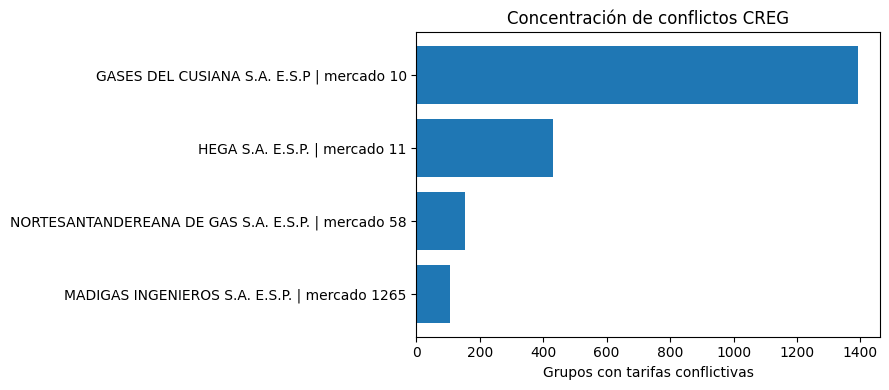

In [27]:
empresas=c[llave[:0]+['ID_EMPRESA','EMPRESA']].drop_duplicates().groupby('ID_EMPRESA').EMPRESA.first()
res_mercado=conf.groupby(['ID_EMPRESA','ID MERCADO']).agg(grupos=('n','size'),registros=('n','sum'),primer_anio=('ANO','min'),ultimo_anio=('ANO','max')).reset_index()
res_mercado['empresa']=res_mercado.ID_EMPRESA.map(empresas)
res_mercado['porcentaje_grupos']=100*res_mercado.grupos/len(conf)
display(res_mercado.sort_values('grupos',ascending=False))
fig,ax=plt.subplots(figsize=(9,4))
t=res_mercado.sort_values('grupos')
ax.barh(t['empresa'].astype(str)+' | mercado '+t['ID MERCADO'].astype(str),t.grupos)
ax.set_xlabel('Grupos con tarifas conflictivas');ax.set_title('Concentración de conflictos CREG')
plt.tight_layout();plt.savefig(OUT/'conflictos_por_mercado.png',dpi=140);plt.show()

**5. Ejemplo verificable y diferencias de tarifa**
Se muestra un caso concreto de conflicto en noviembre de 2005 para el mercado 10 y estrato 3, si está presente. Se preservan los valores originales para permitir una inspección independiente. La comparación se limita a diferencias observadas; no decide cuál tarifa es válida.

In [28]:
ejemplo=c.loc[(c.ANO==2005)&(c.MES==11)&(c['ID MERCADO']==10)&(c.ESTRATO==3)]
display(ejemplo[['ANO','MES','EMPRESA','ID_EMPRESA','ID MERCADO','ESTRATO','MUNICIPIOS']+tarifas+['CONEXION','REINSTALACION','RECONEXION']].head(10))
print('Filas de ejemplo:',len(ejemplo))

,ANO,MES,EMPRESA,ID_EMPRESA,ID MERCADO,ESTRATO,MUNICIPIOS,CARGO_FIJO,RANGO_0,RANGO_21,CONEXION,REINSTALACION,RECONEXION
162127,2005,11,GASES DEL CUSIANA S.A. E.S.P,541,10,3,AGUAZUL - MONTERREY - VILLANUEVA,3019.0,304.0,304.0,359446.0,230177.0,13552.0
162130,2005,11,GASES DEL CUSIANA S.A. E.S.P,541,10,3,AGUAZUL - MONTERREY - VILLANUEVA,3019.0,295.0,295.0,359446.0,230177.0,13552.0


Filas de ejemplo: 2


**6. Impacto sobre series mensuales**
Una proporción global pequeña de conflictos puede destruir la continuidad de series particulares. La serie se define por (ID_EMPRESA, ID MERCADO, ESTRATO); se calcula la proporción de meses observados con conflicto y se detectan series totalmente afectadas. La cobertura aquí es sobre meses presentes en la fuente, no sobre todos los meses calendario posibles.

In [29]:
series=['ID_EMPRESA','ID MERCADO','ESTRATO']
meses_total=diagnostico.groupby(series).size().rename('meses_observados')
meses_conf=conf.groupby(series).size().rename('meses_conflictivos')
impacto=pd.concat([meses_total,meses_conf],axis=1).fillna(0).reset_index()
impacto['meses_conflictivos']=impacto.meses_conflictivos.astype(int)
impacto['pct_meses_conflictivos']=100*impacto.meses_conflictivos/impacto.meses_observados
impacto['serie_sin_meses_confiables']=impacto.meses_conflictivos.eq(impacto.meses_observados)
print('Series totales:',len(impacto),'| afectadas:',int((impacto.meses_conflictivos>0).sum()))
print('Series sin meses no conflictivos:',int(impacto.serie_sin_meses_confiables.sum()))
print('Series con >90% de meses conflictivos:',int((impacto.pct_meses_conflictivos>90).sum()))
display(impacto.loc[impacto.meses_conflictivos>0].sort_values('pct_meses_conflictivos',ascending=False).head(25))

Series totales: 1553 | afectadas: 20
Series sin meses no conflictivos: 3
Series con >90% de meses conflictivos: 13


,ID_EMPRESA,ID MERCADO,ESTRATO,meses_observados,meses_conflictivos,pct_meses_conflictivos,serie_sin_meses_confiables
212,522,58,3,107,107,100.000000,True
262,541,10,1,238,238,100.000000,True
263,541,10,2,238,238,100.000000,True
267,541,10,6,226,224,99.115044,False
265,541,10,4,238,234,98.319328,False
264,541,10,3,238,234,98.319328,False
266,541,10,5,238,224,94.117647,False
1370,26035,11,4,79,72,91.139241,False
1371,26035,11,5,79,72,91.139241,False
1372,26035,11,6,79,72,91.139241,False


**7. Banderas de calidad y selección conservadora CREG**
Se mantienen los registros con valores sospechosos en la tabla auditada. Para el subconjunto preliminar de modelado se excluyen: llaves con tarifas conflictivas, consumo RANGO_0=0, consumo RANGO_21=0, cargos fijos negativos y RANGO_0>20.000. El umbral de 20.000 es solo una regla provisional de cuarentena y deberá contrastarse con fuentes oficiales; no demuestra error. CARGO_FIJO=0 en estratos 1 y 2 se conserva como posible condición estructural. RANGO_0>RANGO_21 se señala sin eliminar automáticamente.

In [30]:
c=c.merge(conf[llave].assign(conflicto_tarifa=True),on=llave,how='left')
c['conflicto_tarifa']=c.conflicto_tarifa.eq(True)
c['duplicado_llave_misma_tarifa']=c.duplicated(llave,keep='first') & ~c.conflicto_tarifa
n_repetidos_no_conf=int(c.duplicado_llave_misma_tarifa.sum())
c=c.loc[~c.duplicado_llave_misma_tarifa].copy()
c['fecha']=pd.to_datetime(dict(year=c.ANO,month=c.MES,day=1),errors='coerce')
c['rango_0_cero_sospechoso']=c.RANGO_0.eq(0)
c['rango_21_cero_sospechoso']=c.RANGO_21.eq(0)
c['cargo_fijo_negativo']=c.CARGO_FIJO.lt(0)
c['cargo_fijo_cero_estratos_3_6']=c.ESTRATO.isin([3,4,5,6])&c.CARGO_FIJO.eq(0)
c['rango_0_mayor_rango_21']=c.RANGO_0.gt(c.RANGO_21)&c.RANGO_21.gt(0)
c['rango_0_extremo_revision']=c.RANGO_0.gt(20000)
c['apto_modelado']=~(c.conflicto_tarifa|c.rango_0_cero_sospechoso|c.rango_21_cero_sospechoso|c.cargo_fijo_negativo|c.rango_0_extremo_revision)
flags=['conflicto_tarifa','rango_0_cero_sospechoso','rango_21_cero_sospechoso','cargo_fijo_negativo','cargo_fijo_cero_estratos_3_6','rango_0_mayor_rango_21','rango_0_extremo_revision']
display(c[flags].sum().rename('registros').to_frame())
print('Duplicado adicional de llave sin conflicto:',n_repetidos_no_conf)
print('Base auditada:',len(c),'| elegibles preliminares:',int(c.apto_modelado.sum()))
assert len(c)==162971 and int(c.apto_modelado.sum())==133282

,registros
conflicto_tarifa,4589
rango_0_cero_sospechoso,496
rango_21_cero_sospechoso,25616
cargo_fijo_negativo,48
cargo_fijo_cero_estratos_3_6,374
rango_0_mayor_rango_21,3434
rango_0_extremo_revision,22


Duplicado adicional de llave sin conflicto: 1
Base auditada: 162971 | elegibles preliminares: 133282


**8. EPM: normalización y separación del universo residencial**
Se lee Año como texto para no convertir 2.020 en el decimal 2,02. Los importes monetarios se convierten respetando punto de miles y coma decimal. Se conservan las columnas originales, se crea una fecha mensual y se delimita el alcance residencial. La exclusión de usuarios no residenciales es filtrado por alcance, no eliminación por mala calidad.

In [31]:
meses={'enero':1,'febrero':2,'marzo':3,'abril':4,'mayo':5,'junio':6,'julio':7,'agosto':8,'septiembre':9,'setiembre':9,'octubre':10,'noviembre':11,'diciembre':12}
e=epm.copy()
for col in ['Cargo Fijo','Cargo por Consumo Menor','Cargo por Consumo Mayor']:
    e[col+'_num']=pd.to_numeric(e[col].str.replace('$','',regex=False).str.replace('.','',regex=False).str.replace(',','.',regex=False),errors='coerce')
e['anio_num']=pd.to_numeric(e['Año'].str.replace('.','',regex=False),errors='coerce')
e['mes_num']=e.Mes.str.strip().str.lower().map(meses)
e['fecha']=pd.to_datetime(dict(year=e.anio_num,month=e.mes_num,day=1),errors='coerce')
e['estrato_num']=pd.to_numeric(e.Estrato,errors='coerce')
e['residencial']=e.Sector.str.strip().str.lower().eq('residencial')
num_cols=['Cargo Fijo_num','Cargo por Consumo Menor_num','Cargo por Consumo Mayor_num']
e['apto_modelado']=e.residencial & e.fecha.notna() & e.estrato_num.between(1,6) & e[num_cols].notna().all(axis=1)
print('Conversiones fallidas:',e[['fecha']+num_cols].isna().sum().to_dict())
print('Residenciales:',int(e.residencial.sum()),'| no residenciales:',int((~e.residencial).sum()))
print('EPM elegibles:',int(e.apto_modelado.sum()))
assert int(e.apto_modelado.sum())==492
print('Ejemplo de conversión:');display(e[['Año','Mes','fecha','Cargo por Consumo Mayor','Cargo por Consumo Mayor_num']].head(3))

Conversiones fallidas: {'fecha': 0, 'Cargo Fijo_num': 0, 'Cargo por Consumo Menor_num': 0, 'Cargo por Consumo Mayor_num': 0}
Residenciales: 492 | no residenciales: 164
EPM elegibles: 492
Ejemplo de conversión:


,Año,Mes,fecha,Cargo por Consumo Mayor,Cargo por Consumo Mayor_num
0,2.020,enero,2020-01-01,"$1.709,03",1709.03
1,2.020,enero,2020-01-01,"$1.709,03",1709.03
2,2.020,enero,2020-01-01,"$1.709,03",1709.03


**9. Verificaciones de integridad y continuidad**
Se verifican fechas, llaves y presencia de seis estratos por mes en el piloto EPM. La llave CREG puede permanecer repetida en la base auditada si existe un conflicto, pero no en la selección elegible. La selección no garantiza series continuas: ese requisito se debe comprobar antes del entrenamiento.

In [32]:
assert not c.loc[c.apto_modelado].duplicated(llave).any(), 'Hay llaves repetidas en CREG elegible'
assert not e.loc[e.apto_modelado].duplicated(['fecha','estrato_num']).any(), 'Hay llaves repetidas en EPM elegible'
meses_epm=e.loc[e.apto_modelado].groupby('fecha').estrato_num.nunique()
print('Meses EPM:',len(meses_epm),'| meses con seis estratos:',int(meses_epm.eq(6).sum()))
assert len(meses_epm)==82 and meses_epm.eq(6).all()
print('CREG elegible por año (últimos 10):')
display(c.groupby('ANO').apto_modelado.agg(['sum','count']).tail(10))
print('Las tasas de selección no equivalen a la meta de cobertura de alertas del proyecto.')

Meses EPM: 82 | meses con seis estratos: 82
CREG elegible por año (últimos 10):


,sum,count
ANO,,
2014,9250,10789
2015,9620,11085
2016,9346,11764
2017,9069,12265
2018,11041,14228
2019,10413,13625
2020,10558,13380
2021,10366,13526
2022,10697,13280


Las tasas de selección no equivalen a la meta de cobertura de alertas del proyecto.


**10. Técnicas aplicadas y descartadas**
| Técnica | Decisión | Fundamento |
|---|---|---|
| Eliminación general | No | Borraría observaciones potencialmente válidas y afectaría series. |
| Eliminación de duplicados exactos | Sí | Repetición verificable, sin pérdida de información única. |
| Conversión/estandarización de formatos | Sí | EPM requiere normalizar moneda, año, mes y estrato. |
| Filtrado de alcance | Sí | Se estudian tarifas residenciales; no residenciales quedan auditadas. |
| Imputación por promedio/modelo | No | Fabricaría tarifas, suavizaría alzas y contaminaría la detección. |
| Imputación aleatoria | No | Añadiría variabilidad no observada y sería difícil de justificar. |
| Recorte de extremos / winsorización | No | Podría borrar las señales que se buscan detectar. |
| Cuarentena provisional de registros ambiguos | Sí | Se evita entrenar con tarifas no resolubles sin destruir los datos. |

Limitación crítica: sin metadatos adicionales no puede atribuirse una causa definitiva a los 1.470 grupos cuyos demás campos son iguales. Se requiere validación documental de empresas/CREG para rehabilitar esas series.

**11. Exportación de evidencias**
Se generan tablas auditables para las decisiones del informe: registros con banderas, grupos conflictivos, resumen por mercado, impacto por serie y tabla ejecutiva de antes/después. Ningún archivo original se sobrescribe.

In [33]:
c.to_csv(
    OUT / 'CREG_auditoria_limpieza.csv',
    index=False,
    encoding='utf-8-sig',
    quoting=1
)
e.to_csv(OUT/'EPM_auditoria_limpieza.csv',index=False)
conf.to_csv(OUT/'CREG_grupos_conflictivos_diagnostico.csv',index=False)
res_mercado.to_csv(OUT/'CREG_conflictos_por_mercado.csv',index=False)
impacto.to_csv(OUT/'CREG_impacto_series.csv',index=False)
resumen=pd.DataFrame([
{'fuente':'CREG','original':len(creg),'duplicados_exactos':exactos,'auditada':len(c),'elegible_preliminar':int(c.apto_modelado.sum())},
{'fuente':'EPM','original':len(epm),'duplicados_exactos':int(epm.duplicated().sum()),'auditada':len(e),'elegible_preliminar':int(e.apto_modelado.sum())}])
resumen.to_csv(OUT/'Resumen_limpieza.csv',index=False)
display(resumen)
print('Archivos generados en:',OUT.resolve())

,fuente,original,duplicados_exactos,auditada,elegible_preliminar
0,CREG,165360,2388,162971,133282
1,EPM,656,0,656,492


Archivos generados en: /content/salidas_guia4


**12. Interpretación final y próximos controles**
Resultado: se eliminan únicamente duplicados verificables; se normalizan formatos EPM; se identifican conflictos tarifarios sistemáticos concentrados en cuatro mercados; se conserva una base auditada y se separa un conjunto de modelado provisional.

Antes del entrenamiento: (i) contrastar tarifas de mercados conflictivos con documentos de la fuente; (ii) revisar unidad y significado de ceros por tipo de cargo; (iii) evaluar continuidad mensual y tamaño mínimo por serie; (iv) validar el umbral exploratorio de 20.000 sin eliminar alzas legítimas; (v) calcular cobertura del detector sobre el universo de mercados/estratos finalmente habilitados.

No afirmar: que las 2.082 llaves sean errores comprobados, que todas las alzas >10% sean anomalías confirmadas o que la tasa de elegibilidad sea equivalente a la cobertura de negocio.

In [34]:
# Verificación de integridad usando el mismo lector CSV que admite la estructura exportada
import csv
ruta = OUT / 'CREG_auditoria_limpieza.csv'
with open(ruta, 'r', encoding='utf-8-sig', newline='') as archivo:
    lector = csv.reader(archivo)
    encabezado = next(lector)
    filas = 0
    for fila in lector:
        filas += 1
        assert len(fila) == len(encabezado), f'Fila {filas} con estructura inesperada'
print('Registros:', filas)
print('Columnas:', len(encabezado))
assert (filas, len(encabezado)) == (162971, 24), 'La estructura del archivo no coincide con lo esperado'
print('Verificación completada correctamente')

Registros: 162971
Columnas: 24
Verificación completada correctamente


---
# Anexo Técnico 3 — Entendimiento inicial de los datos

# Anexo Técnico 3 — Entendimiento inicial de los datos

**Grupo 18 · Gerencia de Proyectos de Analytics · MIAD**  
**Problema:** alerta temprana de alzas atípicas en tarifas de gas natural para usuarios residenciales.

Este notebook integra los análisis exploratorios de Felipe y Víctor. Parte exclusivamente de las **bases auditadas del Anexo Técnico 2**; no vuelve a limpiar las fuentes originales. Los filtros adicionales se usan solo para **análisis de sensibilidad**, sin borrar registros auditados. Las alzas estadísticas no prueban irregularidades tarifarias.

**Reproducción:** cargar `CREG_auditoria_limpieza.csv` y `EPM_auditoria_limpieza.csv` en el mismo directorio del notebook (en Colab, `/content`). Las figuras y tablas se guardan en `salidas_guia4/`.

In [35]:
from pathlib import Path
import numpy as np
import csv
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

BASE = Path.cwd()
OUT = BASE / 'salidas_guia4'
OUT.mkdir(exist_ok=True)
with open(OUT / 'CREG_auditoria_limpieza.csv',
          'r', encoding='utf-8-sig', newline='') as archivo:

    lector = csv.reader(archivo)
    columnas = next(lector)
    c = pd.DataFrame(lector, columns=columnas)

c['fecha'] = pd.to_datetime(c['fecha'], errors='raise')

print("CREG cargada correctamente:", c.shape)
e0 = pd.read_csv(OUT / 'EPM_auditoria_limpieza.csv', low_memory=False, parse_dates=['fecha'])
for df in (c, e0):
    if df['apto_modelado'].dtype == object:
        df['apto_modelado'] = df['apto_modelado'].astype(str).str.lower().eq('true')
for col in ['ANO','MES','ID_EMPRESA','ID MERCADO','ESTRATO','CARGO_FIJO','RANGO_0','RANGO_21']:
    c[col] = pd.to_numeric(c[col], errors='coerce')
for col in ['estrato_num','Cargo Fijo_num','Cargo por Consumo Menor_num','Cargo por Consumo Mayor_num']:
    e0[col] = pd.to_numeric(e0[col], errors='coerce')
assert c.shape == (162971,24) and e0.shape == (656,16), 'Verificar versiones de los archivos auditados'
assert int(c.apto_modelado.sum()) == 133282 and int(e0.apto_modelado.sum()) == 492
m = c.loc[c.apto_modelado].copy()
e = e0.loc[e0.apto_modelado].copy()
e = e.rename(columns={'estrato_num':'ESTRATO','Cargo Fijo_num':'CARGO_FIJO','Cargo por Consumo Menor_num':'RANGO_0','Cargo por Consumo Mayor_num':'RANGO_21'})
e['ESTRATO'] = e['ESTRATO'].astype(int)
e['ANO'] = e.fecha.dt.year; e['MES'] = e.fecha.dt.month
AZUL, NARANJA, GRIS = '#2a78d6', '#eb6834', '#52514e'
print('CREG auditada:',len(c),'| elegible:',len(m),'| EPM auditada:',len(e0),'| residencial:',len(e))
assert not m.duplicated(['ID_EMPRESA','ID MERCADO','ESTRATO','fecha']).any()
assert not e.duplicated(['ESTRATO','fecha']).any()

CREG cargada correctamente: (162971, 24)
CREG auditada: 162971 | elegible: 133282 | EPM auditada: 656 | residencial: 492


## 1. Filtración y sensibilidad (técnica 1)

La elegibilidad procede del Anexo 2. Un filtro adicional de magnitudes inusuales (`RANGO_0 < 100`, `RANGO_21 < 100` o `RANGO_21 > 20.000`) se evalúa **solo como escenario de sensibilidad**. No equivale a errores confirmados ni modifica el universo elegible oficial.

**Nota metodológica:** el filtro adicional es exclusivamente un escenario de sensibilidad. No altera las banderas de elegibilidad del Anexo Técnico 2 ni demuestra que las observaciones señaladas sean erróneas. Las variaciones temporales calculadas después del filtro solo utilizan meses consecutivos; el filtro puede reducir artificialmente la continuidad de algunas series. Las conclusiones generales de niveles se basan en `m` (133.282 elegibles), mientras que las comparaciones filtradas utilizan `a`.


In [36]:
m = c.loc[c.apto_modelado].copy()
m['valor_implausible'] = (m.RANGO_0 < 100) | (m.RANGO_21 < 100) | (m.RANGO_21 > 20000)
print('Elegibles:', len(m))
print('RANGO_0 < 100:', int((m.RANGO_0 < 100).sum()), '| RANGO_21 < 100:', int((m.RANGO_21 < 100).sum()), '| RANGO_21 > 20.000:', int((m.RANGO_21 > 20000).sum()))
print('Registros con valor implausible:', int(m.valor_implausible.sum()), f'({m.valor_implausible.mean()*100:.2f} % de los elegibles)')
print('Mediana de RANGO_21 entre los < 100:', round(m.loc[m.RANGO_21 < 100, 'RANGO_21'].median(), 2))
display(m.loc[m.valor_implausible].groupby(['EMPRESA', 'ID MERCADO']).size().sort_values(ascending=False).head(8).rename('registros').to_frame())
print('Empresas con valores implausibles:', m.loc[m.valor_implausible, 'ID_EMPRESA'].nunique())

# Efecto sobre la variación mensual: con y sin el filtro
serie = ['ID_EMPRESA', 'ID MERCADO', 'ESTRATO']
def variaciones(df):
    df = df.sort_values(serie + ['fecha']).copy()
    ant = df.groupby(serie).fecha.shift()
    df['consecutivo'] = ((df.fecha.dt.year - ant.dt.year) * 12 + (df.fecha.dt.month - ant.dt.month)) == 1
    for col in ['RANGO_0', 'RANGO_21']:
        df['ant_' + col] = df.groupby(serie)[col].shift().where(df.consecutivo)
        df['var_' + col] = (df[col] / df['ant_' + col] - 1) * 100
    return df
sin_filtro = variaciones(m)
a = variaciones(m.loc[~m.valor_implausible])
for nombre, d in [('Sin filtro', sin_filtro), ('Con filtro', a)]:
    v = d.var_RANGO_21.dropna()
    print(f'{nombre}: n={len(v):,} | media {v.mean():.2f} % | desv. {v.std():.1f} | mediana {v.median():.2f} % | máx {v.max():,.0f} % | alzas > 100 %: {int((v > 100).sum())}')
print('Base de análisis CREG:', len(a), 'registros |', a.groupby(serie).ngroups, 'series |', a.groupby(['ID_EMPRESA', 'ID MERCADO']).ngroups, 'pares empresa-mercado')
# Cuantificar el efecto del escenario de sensibilidad sin modificar la base oficial
comparacion_filtro = pd.DataFrame([
    {'escenario':'Elegibles Anexo 2 (sin filtro adicional)', 'registros':len(m), 'series':m.groupby(serie).ngroups, 'variaciones_validas':int(sin_filtro.var_RANGO_21.notna().sum())},
    {'escenario':'Sensibilidad (excluye magnitudes señaladas)', 'registros':len(a), 'series':a.groupby(serie).ngroups, 'variaciones_validas':int(a.var_RANGO_21.notna().sum())}
])
display(comparacion_filtro)


Elegibles: 133282
RANGO_0 < 100: 472 | RANGO_21 < 100: 467 | RANGO_21 > 20.000: 2
Registros con valor implausible: 553 (0.41 % de los elegibles)
Mediana de RANGO_21 entre los < 100: 1.76


registros
EMPRESA                                ID MERCADO           
INGENIERIA Y SERVICIOS S.A. E.S.P.     32                 56
                                       179                42
SURTIDORA DE GAS DEL CARIBE S.A. E.S.P 447                30
                                       866                30
                                       194                30
                                       180                30
                                       20                 28
                                       120                26

Empresas con valores implausibles: 12
Sin filtro: n=129,133 | media 46.89 % | desv. 2121.4 | mediana 0.24 % | máx 127,905 % | alzas > 100 %: 119
Con filtro: n=128,506 | media 0.85 % | desv. 8.9 | mediana 0.24 % | máx 861 % | alzas > 100 %: 43
Base de análisis CREG: 132729 registros | 1287 series | 228 pares empresa-mercado


,escenario,registros,series,variaciones_validas
0,Elegibles Anexo 2 (sin filtro adicional),133282,1287,129133
1,Sensibilidad (excluye magnitudes señaladas),132729,1287,128506


## 2. Extracción de variables temporales (técnica 4)

Las variaciones se calculan **solo entre meses consecutivos de la misma empresa, mercado y estrato**. No se interpreta un salto sobre un hueco temporal como variación mensual. Se preservan ambos escenarios: `sin_filtro` y `a` (sensibilidad).

In [37]:
print(f'Observaciones con mes anterior consecutivo: {a.consecutivo.mean()*100:.1f} %')
print('Variaciones mensuales calculadas (RANGO_21):', int(a.var_RANGO_21.notna().sum()))
L = a.groupby(serie).agg(meses=('fecha', 'size'), inicio=('fecha', 'min'), fin=('fecha', 'max'))
print('Series:', len(L), '| mediana de meses por serie:', int(L.meses.median()))
ok36 = L.meses >= 36
print(f'Series con al menos 36 meses: {int(ok36.sum())} ({ok36.mean()*100:.1f} %) | concentran el {a.set_index(serie).index.isin(L[ok36].index).mean()*100:.1f} % de los registros')
print('Series con datos en 2023:', int((L.fin >= "2023-01-01").sum()), '| de ellas con al menos 36 meses:', int(((L.fin >= "2023-01-01") & ok36).sum()))
e = e.sort_values(['ESTRATO', 'fecha']).copy()
for col in ['RANGO_0', 'RANGO_21']:
    e['var_' + col] = e.groupby('ESTRATO')[col].pct_change() * 100

Observaciones con mes anterior consecutivo: 96.8 %
Variaciones mensuales calculadas (RANGO_21): 128506
Series: 1287 | mediana de meses por serie: 109
Series con al menos 36 meses: 1074 (83.4 %) | concentran el 98.3 % de los registros
Series con datos en 2023: 872 | de ellas con al menos 36 meses: 858


## 3. Estadísticas descriptivas y valores extremos (técnica 5)

Se presentan los niveles de tarifas en la base elegible **sin filtro adicional** y en EPM, para no confundir el análisis de sensibilidad con la depuración del Anexo 2. Después se exploran los cambios mensuales de CREG.

In [38]:
cols = ['CARGO_FIJO','RANGO_0','RANGO_21']
print('CREG elegible (sin filtro adicional)')
display(m[cols].describe(percentiles=[.25,.5,.75,.95,.99]).T.round(2))
print('EPM residencial')
display(e[cols].describe(percentiles=[.25,.5,.75,.95,.99]).T.round(2))
print('Mayores valores de RANGO_21 en CREG elegible')
display(m.nlargest(10,'RANGO_21')[['fecha','EMPRESA','ID MERCADO','ESTRATO','RANGO_0','RANGO_21','CARGO_FIJO']])

CREG elegible (sin filtro adicional)


,count,mean,std,min,25%,50%,75%,95%,99%,max
CARGO_FIJO,133282.0,2066.39,1823.45,0.0,0.00,2201.40,3379.62,5189.16,6210.00,9731.61
RANGO_0,133282.0,1473.16,871.72,0.8,843.08,1297.79,1938.74,3045.49,4099.98,10748.23
RANGO_21,133282.0,1714.39,1024.91,1.0,1116.00,1603.00,2175.00,3197.64,4884.19,131271.00


EPM residencial


,count,mean,std,min,25%,50%,75%,95%,99%,max
CARGO_FIJO,492.0,2716.82,1985.56,0.00,0.00,3762.18,4199.21,5032.98,5251.55,5267.65
RANGO_0,492.0,2210.44,782.03,804.82,1548.04,2293.89,2781.14,3401.30,4071.65,4271.86
RANGO_21,492.0,2574.55,513.69,1650.61,2219.30,2472.56,2879.86,3517.06,4071.65,4271.86


Mayores valores de RANGO_21 en CREG elegible


,fecha,EMPRESA,ID MERCADO,ESTRATO,RANGO_0,RANGO_21,CARGO_FIJO
55749,2019-07-01,GASES DE LA GUAJIRA S.A. E.S.P.,17,1,677.00,131271.00,0.00
55753,2019-07-01,GASES DE LA GUAJIRA S.A. E.S.P.,17,2,846.00,131271.00,0.00
76376,2018-02-01,KEOPS & ASOCIADOS S.A.S E.S.P,585,5,10748.23,10748.23,5347.23
76380,2018-02-01,KEOPS & ASOCIADOS S.A.S E.S.P,585,6,10748.23,10748.23,5347.23
78524,2017-12-01,KEOPS & ASOCIADOS S.A.S E.S.P,585,5,10712.28,10712.28,5333.70
78527,2017-12-01,KEOPS & ASOCIADOS S.A.S E.S.P,585,6,10712.28,10712.28,5333.70
68062,2018-09-01,KEOPS & ASOCIADOS S.A.S E.S.P,585,5,10542.58,10542.58,5347.46
68065,2018-09-01,KEOPS & ASOCIADOS S.A.S E.S.P,585,6,10542.58,10542.58,5347.46
69342,2018-08-01,KEOPS & ASOCIADOS S.A.S E.S.P,585,5,10542.57,10542.57,5347.46
69347,2018-08-01,KEOPS & ASOCIADOS S.A.S E.S.P,585,6,10542.57,10542.57,5347.46


,registros,cargo_fijo_mediana,rango_0_mediana,rango_21_mediana
ESTRATO,,,,
1,23826,0.0,810.0,1512.0
2,23900,0.0,998.0,1510.0
3,23975,2811.0,1521.0,1521.0
4,21104,2769.0,1521.0,1521.0
5,20086,3264.0,1837.0,1837.0
6,19838,3274.0,1843.0,1843.0


,RANGO_0,RANGO_21
n,128506.00,128506.00
p01,-15.51,-15.78
p05,-5.56,-6.43
mediana,0.28,0.24
p95,7.67,8.65
p99,20.36,20.02
sin_cambio_%,7.25,9.85
dentro_±5_%,84.49,80.72
alzas_>10_%,3.26,3.89
bajas_<-10_%,2.06,2.36


Alzas RANGO_21 > 10 %: 4997 | > 20 %: 1289 | > 50 %: 210 | > 100 %: 43


,R0_mediana,R0_p95,R0_alzas_>10_%,R21_mediana,R21_p95,R21_alzas_>10_%
ESTRATO,,,,,,
1,0.30,4.62,1.94,0.27,8.35,3.70
2,0.30,4.81,1.98,0.27,8.36,3.71
3,0.19,8.62,3.86,0.19,8.62,3.86
4,0.22,8.89,4.03,0.23,8.89,4.04
5,0.20,8.92,4.05,0.21,8.92,4.06
6,0.21,8.91,4.03,0.21,8.91,4.04


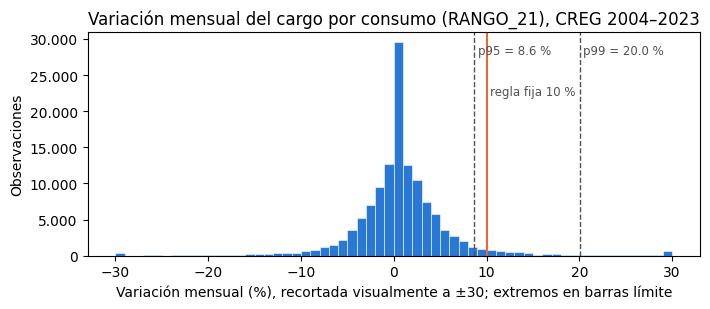

In [39]:
nivel = a.groupby('ESTRATO').agg(registros=('RANGO_21', 'size'), cargo_fijo_mediana=('CARGO_FIJO', 'median'),
                                 rango_0_mediana=('RANGO_0', 'median'), rango_21_mediana=('RANGO_21', 'median')).round(0)
display(nivel)

def resumen_var(v):
    v = v.dropna()
    return pd.Series({'n': len(v), 'p01': v.quantile(.01), 'p05': v.quantile(.05), 'mediana': v.median(), 'p95': v.quantile(.95),
                      'p99': v.quantile(.99), 'sin_cambio_%': (v == 0).mean()*100, 'dentro_±5_%': (v.abs() <= 5).mean()*100,
                      'alzas_>10_%': (v > 10).mean()*100, 'bajas_<-10_%': (v < -10).mean()*100})
dist = pd.DataFrame({'RANGO_0': resumen_var(a.var_RANGO_0), 'RANGO_21': resumen_var(a.var_RANGO_21)}).round(2)
display(dist)
v = a.var_RANGO_21.dropna()
print('Alzas RANGO_21 > 10 %:', int((v > 10).sum()), '| > 20 %:', int((v > 20).sum()), '| > 50 %:', int((v > 50).sum()), '| > 100 %:', int((v > 100).sum()))
por_estrato = a.groupby('ESTRATO').apply(lambda d: pd.Series({
    'R0_mediana': d.var_RANGO_0.median(), 'R0_p95': d.var_RANGO_0.quantile(.95), 'R0_alzas_>10_%': (d.var_RANGO_0.dropna() > 10).mean()*100,
    'R21_mediana': d.var_RANGO_21.median(), 'R21_p95': d.var_RANGO_21.quantile(.95), 'R21_alzas_>10_%': (d.var_RANGO_21.dropna() > 10).mean()*100}), include_groups=False).round(2)
display(por_estrato)

fig, ax = plt.subplots(figsize=(7.2, 3.2))
ax.hist(v.clip(-30, 30), bins=np.arange(-30, 31, 1), color=AZUL, edgecolor='white', linewidth=0.4)
for x, t in [(v.quantile(.95), 'p95'), (v.quantile(.99), 'p99')]:
    ax.axvline(x, color=GRIS, lw=1, ls='--'); ax.text(x + 0.4, ax.get_ylim()[1]*0.9, f'{t} = {x:.1f} %', color=GRIS, fontsize=8.5)
ax.axvline(10, color=NARANJA, lw=1.5); ax.text(10.4, ax.get_ylim()[1]*0.72, 'regla fija 10 %', color=GRIS, fontsize=8.5)
ax.set_title('Variación mensual del cargo por consumo (RANGO_21), CREG 2004–2023')
ax.set_xlabel('Variación mensual (%), recortada visualmente a ±30; extremos en barras límite'); ax.set_ylabel('Observaciones')
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:,.0f}'.replace(',', '.')))
plt.tight_layout(); plt.savefig(OUT / 'fig3_distribucion_variacion.png', dpi=200); plt.show()

### 3.1. Contexto de dos casos extremos

El mercado 17 muestra un pico excepcional de `RANGO_21` en julio de 2019; el mercado 585 presenta niveles elevados durante varios meses y un cambio de nivel a comienzos de 2019. Estas son señales **descriptivas**, no irregularidades confirmadas.

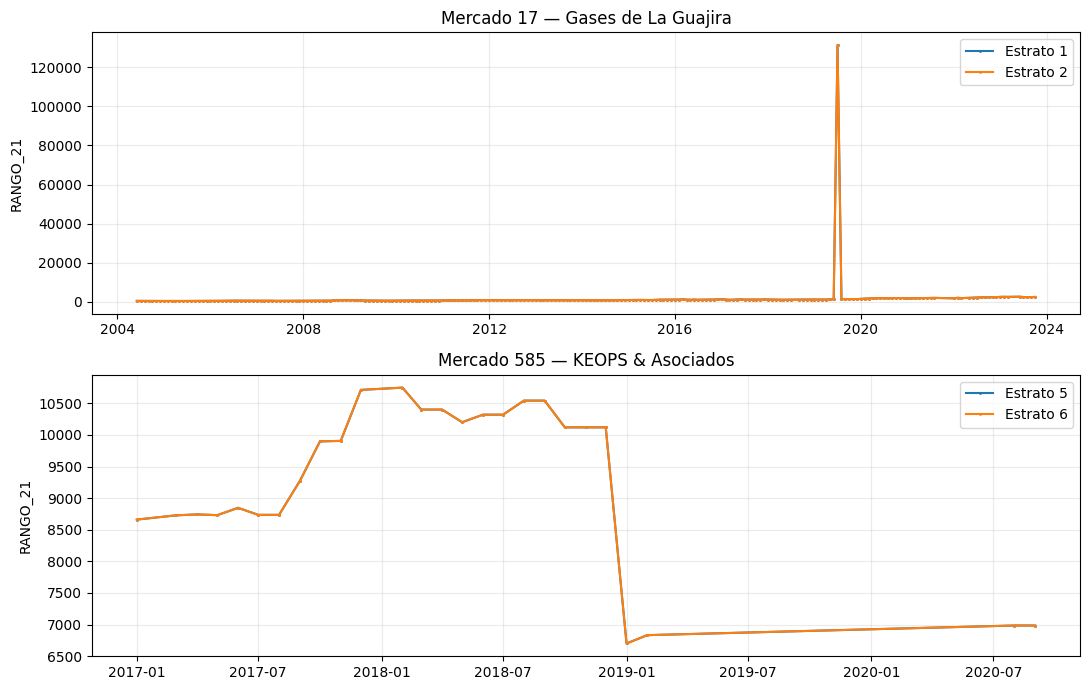

In [40]:
casos = [(17,[1,2],'Mercado 17 — Gases de La Guajira'),(585,[5,6],'Mercado 585 — KEOPS & Asociados')]
fig,axs=plt.subplots(2,1,figsize=(11,7))
for ax,(mercado,estratos,titulo) in zip(axs,casos):
    d=m.loc[(m['ID MERCADO']==mercado)&m.ESTRATO.isin(estratos)].sort_values('fecha')
    for est in estratos:
        s=d.loc[d.ESTRATO==est]
        ax.plot(s.fecha,s.RANGO_21,marker='.',markersize=2,label=f'Estrato {est}')
    ax.set_title(titulo);ax.set_ylabel('RANGO_21');ax.legend();ax.grid(alpha=.25)
plt.tight_layout();plt.savefig(OUT/'P3_casos_extremos.png',dpi=160);plt.show()

## 4. Segmentación temporal y por estrato (técnica 7)

Se comparan meses calendario, años y estratos de CREG, y se estudian los eventos mensuales de EPM sin contar cada estrato como un evento independiente.

ANO,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023
n,1089.00,1620.00,1846.00,2129.00,2631.00,3327.00,3957.00,5080.00,5971.00,6555.00,8869.00,9504.00,9058.00,8599.00,10620.00,10194.00,10113.00,10218.00,10311.00,6815.00
mediana_var_%,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.46,1.16,0.61,0.00,0.75,0.41,0.47,0.60,1.01,0.00
mediana_|var|_%,0.30,0.50,0.90,1.23,1.69,1.91,1.23,1.77,0.87,1.28,2.17,2.99,3.09,1.70,2.17,1.86,2.66,1.73,1.93,2.99
alzas_>10_%,3.76,4.63,2.44,5.54,10.30,4.90,2.75,4.84,2.93,2.55,5.71,4.97,4.71,2.48,2.59,4.93,4.84,2.20,1.91,4.11
tarifa_plena_mediana,414.00,504.00,594.00,596.00,697.00,768.00,773.00,912.00,1000.00,1068.00,1263.00,1413.00,1544.00,1633.00,1540.00,1699.00,1936.00,1985.00,2241.00,2586.00


MES,1,2,3,4,5,6,7,8,9,10,11,12
n,10228.00,10505.00,10692.00,10749.00,10786.00,10761.00,10977.00,11038.00,11156.00,10620.00,10456.00,10538.00
mediana_var_%,1.38,0.48,0.80,0.00,0.00,0.00,0.83,-0.01,0.47,0.90,0.00,0.89
mediana_|var|_%,3.43,2.41,2.04,1.97,1.79,1.80,2.09,1.65,1.78,2.02,1.52,2.14
alzas_>10_%,9.95,4.33,4.22,4.37,3.20,2.04,4.64,1.80,3.92,3.28,2.23,2.97


Alzas > 10 % en enero: 9.9 % | en los demás meses: 3.4 %
Participación de enero en todas las alzas > 10 %: 20.4 %
Tarifa plena mediana (estrato 4): 414 en 2004 y 2586 en 2023 (6.2 veces; 10.1 % anual compuesto)


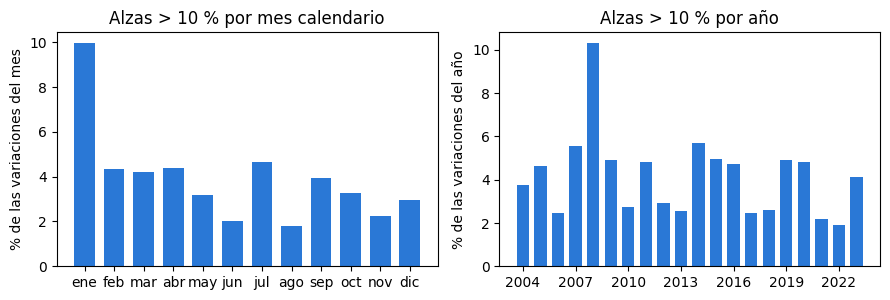

In [41]:
seg = lambda d: pd.Series({'n': d.var_RANGO_21.notna().sum(), 'mediana_var_%': d.var_RANGO_21.median(),
                           'mediana_|var|_%': d.var_RANGO_21.abs().median(), 'alzas_>10_%': (d.var_RANGO_21.dropna() > 10).mean()*100})
por_anio = a.groupby('ANO').apply(seg, include_groups=False).round(2)
por_anio['tarifa_plena_mediana'] = a.loc[a.ESTRATO == 4].groupby('ANO').RANGO_21.median().round(0)
por_mes = a.groupby('MES').apply(seg, include_groups=False).round(2)
display(por_anio.T); display(por_mes.T)
resto = a.loc[a.MES != 1, 'var_RANGO_21'].dropna()
print(f'Alzas > 10 % en enero: {por_mes.loc[1, "alzas_>10_%"]:.1f} % | en los demás meses: {(resto > 10).mean()*100:.1f} %')
print(f'Participación de enero en todas las alzas > 10 %: {(a.loc[a.var_RANGO_21 > 10, "MES"] == 1).mean()*100:.1f} %')
t04, t23 = por_anio.loc[2004, 'tarifa_plena_mediana'], por_anio.loc[2023, 'tarifa_plena_mediana']
print(f'Tarifa plena mediana (estrato 4): {t04:.0f} en 2004 y {t23:.0f} en 2023 ({t23/t04:.1f} veces; {((t23/t04)**(1/19)-1)*100:.1f} % anual compuesto)')

fig, axs = plt.subplots(1, 2, figsize=(9, 3.1))
axs[0].bar(por_mes.index, por_mes['alzas_>10_%'], color=AZUL, width=0.7)
axs[0].set_title('Alzas > 10 % por mes calendario'); axs[0].set_ylabel('% de las variaciones del mes'); axs[0].set_xticks(range(1, 13))
axs[0].set_xticklabels(['ene', 'feb', 'mar', 'abr', 'may', 'jun', 'jul', 'ago', 'sep', 'oct', 'nov', 'dic'])
axs[1].bar(por_anio.index, por_anio['alzas_>10_%'], color=AZUL, width=0.7)
axs[1].set_title('Alzas > 10 % por año'); axs[1].set_ylabel('% de las variaciones del año'); axs[1].set_xticks(range(2004, 2024, 3))
for ax in axs: ax.grid(axis='x', visible=False)
plt.tight_layout(); plt.savefig(OUT / 'fig3_alzas_por_mes_y_anio.png', dpi=200); plt.show()

,count,mean,std,min,median,max
ESTRATO,,,,,,
1,81,1.0,4.3,-7.93,0.36,17.75
2,81,1.0,4.3,-7.93,0.36,17.75
3,81,1.0,4.3,-7.93,0.36,17.75
4,81,1.0,4.3,-7.93,0.36,17.75
5,81,1.0,4.3,-7.93,0.36,17.75
6,81,1.0,4.3,-7.93,0.36,17.75


Eventos EPM con alzas >10 % en algún estrato:


,fecha,variacion_mediana_pct,variacion_minima_pct,variacion_maxima_pct,estratos_alza_10
1,2020-03-01,10.68,10.68,10.68,6
3,2020-05-01,11.12,11.12,11.12,6
60,2025-02-01,17.75,17.75,17.75,6
72,2026-02-01,16.34,16.34,16.34,6


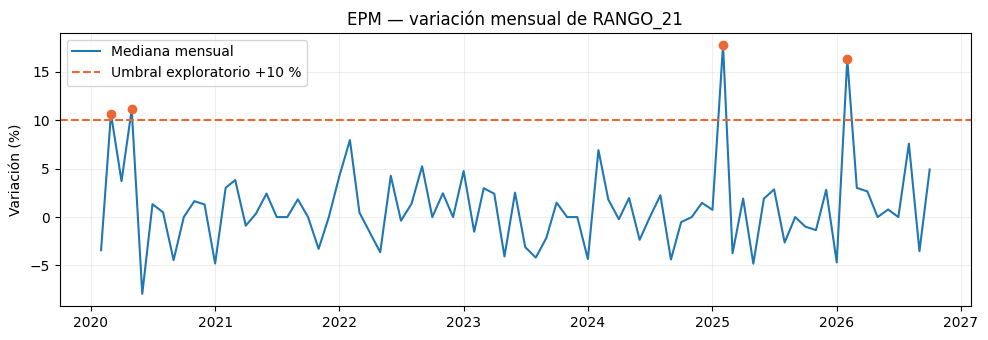

Medianas EPM por estrato:


,CARGO_FIJO,RANGO_0,RANGO_21
ESTRATO,,,
1,0.00,1226.30,2400.46
2,0.00,1524.96,2400.46
3,3808.12,2400.46,2400.46
4,3808.12,2400.46,2400.46
5,4569.74,2880.56,2880.56
6,4569.74,2880.56,2880.56


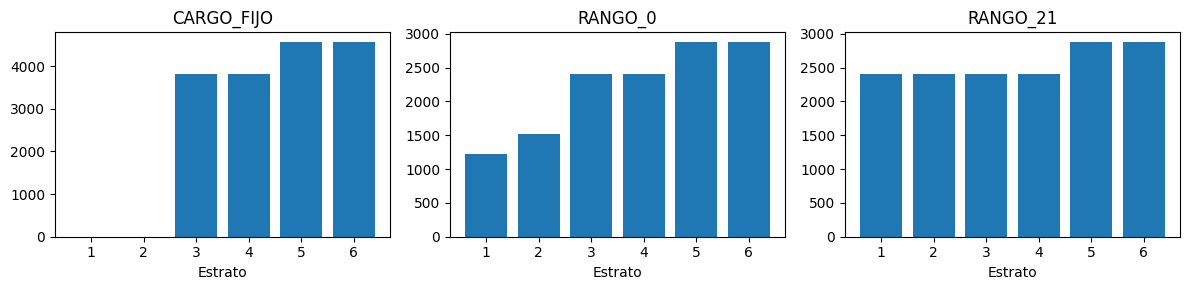

In [42]:
e['variacion_mensual_pct']=e.groupby('ESTRATO')['RANGO_21'].pct_change(fill_method=None)*100
resumen_epm=e.groupby('ESTRATO')['variacion_mensual_pct'].agg(['count','mean','std','min','median','max']).round(2)
display(resumen_epm)
eventos=e.groupby('fecha').agg(variacion_mediana_pct=('variacion_mensual_pct','median'),
    variacion_minima_pct=('variacion_mensual_pct','min'),variacion_maxima_pct=('variacion_mensual_pct','max'),
    estratos_alza_10=('variacion_mensual_pct',lambda s:(s>10).sum())).dropna().reset_index()
relevantes=eventos.loc[eventos.estratos_alza_10>0]
print('Eventos EPM con alzas >10 % en algún estrato:');display(relevantes.round(2))
fig,ax=plt.subplots(figsize=(10,3.5))
ax.plot(eventos.fecha,eventos.variacion_mediana_pct,label='Mediana mensual')
ax.axhline(10,color=NARANJA,ls='--',label='Umbral exploratorio +10 %')
ax.scatter(relevantes.fecha,relevantes.variacion_mediana_pct,color=NARANJA,zorder=3)
ax.set(title='EPM — variación mensual de RANGO_21',ylabel='Variación (%)');ax.legend();ax.grid(alpha=.2)
plt.tight_layout();plt.savefig(OUT/'P3_eventos_EPM.png',dpi=160);plt.show()
tarifas_estrato=e.groupby('ESTRATO')[['CARGO_FIJO','RANGO_0','RANGO_21']].median().round(2)
print('Medianas EPM por estrato:');display(tarifas_estrato)
fig,axs=plt.subplots(1,3,figsize=(12,3))
for ax,col in zip(axs,['CARGO_FIJO','RANGO_0','RANGO_21']):
    ax.bar(tarifas_estrato.index.astype(str),tarifas_estrato[col]);ax.set_title(col);ax.set_xlabel('Estrato')
plt.tight_layout();plt.savefig(OUT/'P3_estratos_EPM.png',dpi=160);plt.show()

## 5. Continuidad temporal y no imputación (técnica 2 — no se aplica)

La ausencia de meses se documenta sin fabricar tarifas. La cobertura se mide entre el primer y último mes de cada serie; no garantiza que cubra todo el periodo 2004–2023.

In [43]:
serie=['ID_EMPRESA','ID MERCADO','ESTRATO']
meses=m[serie+['fecha']].drop_duplicates()
continuidad=meses.groupby(serie).agg(inicio=('fecha','min'),fin=('fecha','max'),meses=('fecha','nunique')).reset_index()
continuidad['meses_calendario']=(continuidad.fin.dt.year-continuidad.inicio.dt.year)*12+continuidad.fin.dt.month-continuidad.inicio.dt.month+1
continuidad['cobertura_pct']=continuidad.meses/continuidad.meses_calendario*100
print('Series:',len(continuidad),'| >=36 meses:',int((continuidad.meses>=36).sum()),'| cobertura completa:',int((continuidad.cobertura_pct==100).sum()),'| <80 %:',int((continuidad.cobertura_pct<80).sum()))
display(continuidad[['meses','cobertura_pct']].describe().round(2))
print('Meses faltantes entre inicio y fin:',int((continuidad.meses_calendario-continuidad.meses).sum()))

Series: 1287 | >=36 meses: 1074 | cobertura completa: 408 | <80 %: 288


,meses,cobertura_pct
count,1287.00,1287.00
mean,103.56,89.14
std,64.41,17.59
min,1.00,1.85
25%,50.00,84.27
50%,112.00,98.29
75%,147.00,100.00
max,238.00,100.00


Meses faltantes entre inicio y fin: 13257


## 6. Reducción de dimensionalidad (técnica 3)

PCA sobre 12 cargos de consumo por empresa–mercado–mes con los seis estratos disponibles. Es exploratorio; no se utiliza como predictor ni prueba de causalidad.
**Interpretación prevista:** PCA se calcula sobre observaciones completas y transformadas logarítmicamente, luego estandarizadas. La varianza explicada corresponde a este conjunto seleccionado, no a todas las series CREG. Una primera componente dominante indica covariación/redundancia en los niveles, pero no valida capacidad de detección ni justifica eliminar variables sin evaluación posterior.


In [44]:
ig = a.groupby('ESTRATO').apply(lambda d: pd.Series({'RANGO_0 = RANGO_21 (%)': np.isclose(d.RANGO_0, d.RANGO_21).mean()*100,
                                                     'mediana RANGO_0 / RANGO_21': (d.RANGO_0 / d.RANGO_21).median()}), include_groups=False).round(3)
display(ig)
idx = ['ID_EMPRESA', 'ID MERCADO', 'fecha']
p21 = a.pivot_table(index=idx, columns='ESTRATO', values='RANGO_21'); p0 = a.pivot_table(index=idx, columns='ESTRATO', values='RANGO_0')
def pct_igual(x, y, factor=1.0, tol=0.005):
    ok = x.notna() & y.notna(); return np.isclose(x[ok] / y[ok], factor, atol=tol).mean() * 100
print(f'RANGO_21: estrato 1 = estrato 4 en {pct_igual(p21[1], p21[4]):.1f} % de los mercado-mes | 2 = 4: {pct_igual(p21[2], p21[4]):.1f} % | 3 = 4: {pct_igual(p21[3], p21[4]):.1f} %')
print(f'RANGO_21: estrato 5 = estrato 6 en {pct_igual(p21[5], p21[6]):.1f} % | estrato 5 = 1,2 × estrato 4 en {pct_igual(p21[5], p21[4], 1.2):.1f} %')
print('RANGO_0 relativo al estrato 4 (mediana):', (p0.div(p0[4], axis=0)).median().round(3).to_dict())
r1 = (p0[1] / p21[4]).dropna(); r2 = (p0[2] / p21[4]).dropna()
print(f'Factor estrato 1 (RANGO_0 / tarifa plena): mediana {r1.median():.3f}, p10–p90 {r1.quantile(.1):.3f}–{r1.quantile(.9):.3f}')
print(f'Factor estrato 2 (RANGO_0 / tarifa plena): mediana {r2.median():.3f}, p10–p90 {r2.quantile(.1):.3f}–{r2.quantile(.9):.3f}')

X = pd.concat([p0.add_prefix('R0_e'), p21.add_prefix('R21_e')], axis=1).dropna()
pca = PCA().fit(StandardScaler().fit_transform(np.log(X)))
ve = pca.explained_variance_ratio_ * 100
print(f'ACP sobre {len(X):,} mercado-mes con los 12 cargos: PC1 {ve[0]:.1f} % | PC2 {ve[1]:.1f} % | PC3 {ve[2]:.1f} % | acumulado 3 componentes {ve[:3].sum():.1f} %')
# Interpretación de cargas: identificar qué variables contribuyen a PC1
cargas_pca = pd.Series(pca.components_[0], index=X.columns, name='carga_PC1')
print('Cargas de PC1 (ordenadas por magnitud absoluta):')
display(cargas_pca.reindex(cargas_pca.abs().sort_values(ascending=False).index).round(3).to_frame())
print('Advertencia: PCA exploratorio; la varianza explicada no es una métrica predictiva.')


,RANGO_0 = RANGO_21 (%),mediana RANGO_0 / RANGO_21
ESTRATO,,
1,0.336,0.51
2,0.402,0.63
3,99.358,1.00
4,99.408,1.00
5,98.994,1.00
6,98.936,1.00


RANGO_21: estrato 1 = estrato 4 en 90.9 % de los mercado-mes | 2 = 4: 90.9 % | 3 = 4: 100.0 %
RANGO_21: estrato 5 = estrato 6 en 100.0 % | estrato 5 = 1,2 × estrato 4 en 94.0 %
RANGO_0 relativo al estrato 4 (mediana): {1: 0.508, 2: 0.627, 3: 1.0, 4: 1.0, 5: 1.2, 6: 1.2}
Factor estrato 1 (RANGO_0 / tarifa plena): mediana 0.508, p10–p90 0.437–0.714
Factor estrato 2 (RANGO_0 / tarifa plena): mediana 0.627, p10–p90 0.547–0.860
ACP sobre 19,667 mercado-mes con los 12 cargos: PC1 97.2 % | PC2 2.6 % | PC3 0.1 % | acumulado 3 componentes 99.9 %
Cargas de PC1 (ordenadas por magnitud absoluta):


,carga_PC1
ESTRATO,
R21_e4,0.292
R21_e3,0.292
R0_e3,0.292
R0_e4,0.292
R21_e1,0.292
R21_e2,0.292
R0_e6,0.292
R0_e5,0.292
R21_e6,0.292


Advertencia: PCA exploratorio; la varianza explicada no es una métrica predictiva.


## 7. Variables explicativas y referencia de persistencia (técnica 8)

Se analizan asociaciones descriptivas y el error de un pronóstico ingenuo que repite el último valor mensual. La **variación nacional del mismo mes** es contemporánea y no puede utilizarse directamente como predictor disponible al inicio del mes. Los resultados no constituyen validación temporal fuera de muestra.
**Precaución de fuga temporal:** `var_nacional` se calcula usando observaciones contemporáneas del mismo mes, incluida potencialmente la serie objetivo. Por tanto, es una asociación **descriptiva**, no una variable disponible de forma garantizada al momento del pronóstico. Los rezagos solo serían utilizables tras verificar disponibilidad y partición cronológica. La persistencia se resume *in-sample* como referencia descriptiva, sin validación fuera de muestra.


In [45]:
d = a.copy()
d['var_nacional'] = d.groupby('fecha').var_RANGO_21.transform('median')
d['var_mes_anterior'] = d.groupby(serie).var_RANGO_21.shift().where(d.consecutivo)
f12 = d[serie + ['fecha', 'var_RANGO_21']].copy(); f12['fecha'] = f12.fecha + pd.DateOffset(years=1)
d = d.merge(f12.rename(columns={'var_RANGO_21': 'var_hace_12_meses'}), on=serie + ['fecha'], how='left')
d['enero'] = (d.MES == 1).astype(int)
cand = ['var_nacional', 'var_mes_anterior', 'var_hace_12_meses', 'enero', 'ESTRATO', 'ANO']
corr = d[['var_RANGO_21'] + cand].corr(method='spearman')['var_RANGO_21'].drop('var_RANGO_21').round(3)
display(corr.rename('Spearman con la variación mensual').to_frame())
print('Correlación del nivel de RANGO_21 con el nivel del mes anterior:', round(a[['RANGO_21', 'ant_RANGO_21']].dropna().corr().iloc[0, 1], 3))

filas = []
for col in ['RANGO_0', 'RANGO_21']:
    for nombre, mask in [('2004–2023', a.ANO.between(2004, 2023)), ('2004–2019', a.ANO.between(2004, 2019)), ('2020–2023', a.ANO.between(2020, 2023))]:
        err = (a.loc[mask, col] - a.loc[mask, 'ant_' + col]).abs().dropna(); ape = a.loc[mask, 'var_' + col].abs().dropna()
        filas.append({'cargo': col, 'periodo': nombre, 'MAE ($/m³)': err.mean(), 'error absoluto mediano ($/m³)': err.median(),
                      'error porcentual mediano (%)': ape.median(), 'error porcentual p90 (%)': ape.quantile(.9)})
persistencia = pd.DataFrame(filas).round(2); display(persistencia)

,Spearman con la variación mensual
var_nacional,0.449
var_mes_anterior,-0.107
var_hace_12_meses,0.094
enero,0.078
ESTRATO,0.003
ANO,0.065


Correlación del nivel de RANGO_21 con el nivel del mes anterior: 0.991


,cargo,periodo,MAE ($/m³),error absoluto mediano ($/m³),error porcentual mediano (%),error porcentual p90 (%)
0,RANGO_0,2004–2023,45.84,16.24,1.23,6.76
1,RANGO_0,2004–2019,37.01,11.00,1.01,6.67
2,RANGO_0,2020–2023,67.30,34.00,1.81,6.96
3,RANGO_21,2004–2023,57.07,30.12,2.00,7.57
4,RANGO_21,2004–2019,49.18,25.00,1.89,7.82
5,RANGO_21,2020–2023,76.26,49.03,2.37,7.05


## 8. Agrupación exploratoria de mercados (técnica 9)

K-means se aplica a perfiles descriptivos de mercados con al menos 36 variaciones observadas; los grupos son perfiles analíticos, no categorías regulatorias ni detecciones confirmadas.

In [46]:
ref = a.loc[a.ESTRATO.isin([3, 4])].sort_values('ESTRATO', ascending=False).drop_duplicates(['ID_EMPRESA', 'ID MERCADO', 'fecha'])
perfil = ref.groupby(['ID_EMPRESA', 'ID MERCADO']).apply(lambda x: pd.Series({
    'meses': x.var_RANGO_21.notna().sum(), 'sin_cambio_%': (x.var_RANGO_21.dropna() == 0).mean()*100,
    'cambio_tipico_%': x.var_RANGO_21.abs().median(), 'alzas_>10_%': (x.var_RANGO_21.dropna() > 10).mean()*100,
    'tarifa_mediana': x.RANGO_21.median()}), include_groups=False)
perfil = perfil.loc[perfil.meses >= 36].copy()
feats = ['sin_cambio_%', 'cambio_tipico_%', 'alzas_>10_%']
Z = StandardScaler().fit_transform(perfil[feats])
sil = {k: silhouette_score(Z, KMeans(k, n_init=20, random_state=18).fit_predict(Z)) for k in range(2, 7)}
print('Mercados perfilados:', len(perfil), '| silueta por k:', {k: round(s, 3) for k, s in sil.items()})
k = max(sil, key=sil.get)
perfil['grupo'] = KMeans(k, n_init=20, random_state=18).fit_predict(Z)
orden = perfil.groupby('grupo')['cambio_tipico_%'].median().sort_values().index
perfil['grupo'] = perfil.grupo.map({g: i + 1 for i, g in enumerate(orden)})
grupos = perfil.groupby('grupo').agg(mercados=('meses', 'size'), sin_cambio=('sin_cambio_%', 'median'), cambio_tipico=('cambio_tipico_%', 'median'),
                                     alzas_10=('alzas_>10_%', 'median'), tarifa_mediana=('tarifa_mediana', 'median')).round(2)
print('k elegido:', k); display(grupos)
print('Mercado 12 (Valle de Aburrá):'); display(perfil.xs(12, level='ID MERCADO').round(2))

Mercados perfilados: 189 | silueta por k: {2: np.float64(0.403), 3: np.float64(0.455), 4: np.float64(0.452), 5: np.float64(0.449), 6: np.float64(0.405)}
k elegido: 3


,mercados,sin_cambio,cambio_tipico,alzas_10,tarifa_mediana
grupo,,,,,
1,30,29.69,1.58,2.51,1363.64
2,111,0.76,2.02,2.31,1756.20
3,48,1.40,3.23,7.64,1437.60


Mercado 12 (Valle de Aburrá):


,meses,sin_cambio_%,cambio_tipico_%,alzas_>10_%,tarifa_mediana,grupo
ID_EMPRESA,,,,,,
564,228.0,30.26,2.2,3.51,856.95,1


## 9. Información complementaria CREG–EPM (técnica 6)

Se evalúan los patrones por estrato y la posibilidad de prolongar el piloto EPM. El mercado 12 solo se considera equivalente después de comprobar su identificación y la concordancia de valores en meses superpuestos. Un gráfico de fuentes superpuestas **no demuestra por sí solo un empalme válido**.
**Criterio de conciliación:** una coincidencia parcial no basta para construir una serie empalmada. Se auditan diferencias por fecha y su magnitud; además de identificar el mercado, se debe verificar la empresa y el alcance geográfico. Los registros no coincidentes permanecen sin resolver.


EPM: igualdad RANGO_21 estratos 1–4 (% meses): 100.0
EPM: igualdad estratos 5 y 6 (% meses): 100.0
EPM: meses con alza >10 % en estrato 3: 4
Empresas en CREG mercado 12:  ID_EMPRESA                              EMPRESA
        564 EMPRESAS PUBLICAS DE MEDELLIN E.S.P.
Meses superpuestos: 41 | coincidencia (tolerancia 0.01): 87.8
Meses discrepantes: 5 | diferencia máxima absoluta: 47.71
Diferencias entre fuentes (solo meses discrepantes):


,CREG_RANGO_21,EPM_RANGO_21,diferencia_absoluta,diferencia_relativa_pct,coincide_tol_001
fecha,,,,,
2023-07-01,2553.65,2505.94,47.71,1.904,False
2022-03-01,2276.07,2244.31,31.76,1.415,False
2022-01-01,2080.16,2069.34,10.82,0.523,False
2022-02-01,2235.75,2234.04,1.71,0.077,False
2022-04-01,2206.46,2207.85,1.39,0.063,False


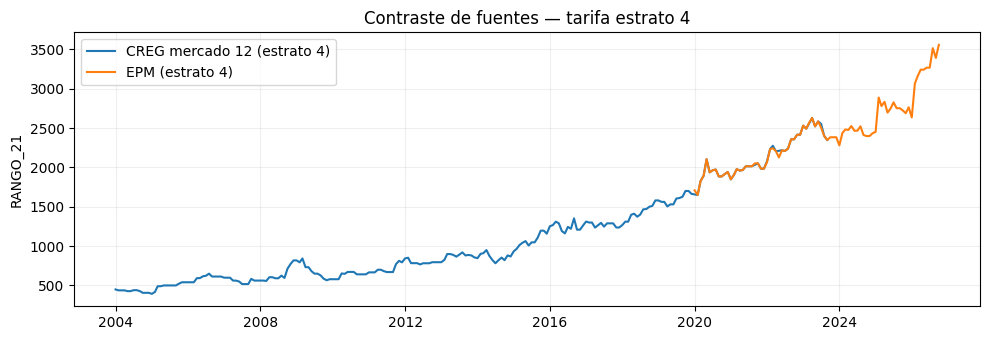

No se exporta empalme automático: revisar discrepancias de origen


In [47]:
pe21=e.pivot(index='fecha',columns='ESTRATO',values='RANGO_21')
pe0=e.pivot(index='fecha',columns='ESTRATO',values='RANGO_0')
print('EPM: igualdad RANGO_21 estratos 1–4 (% meses):',round(np.isclose(pe21[[1,2,3]].to_numpy(),pe21[[4]].to_numpy()).all(axis=1).mean()*100,1))
print('EPM: igualdad estratos 5 y 6 (% meses):',round(np.isclose(pe21[5],pe21[6]).mean()*100,1))
print('EPM: meses con alza >10 % en estrato 3:',int((e.loc[e.ESTRATO==3,'variacion_mensual_pct']>10).sum()))
# Restringir al mercado 12 y al proveedor EPM, sin elegir arbitrariamente un registro por fecha
c12=c.loc[(c['ID MERCADO']==12)&(c.ESTRATO==4)&c.RANGO_21.gt(0)].copy()
print('Empresas en CREG mercado 12:',c12[['ID_EMPRESA','EMPRESA']].drop_duplicates().to_string(index=False))
# Comprobar un único valor por mes antes de empalmar
nval=c12.groupby('fecha').RANGO_21.nunique()
if (nval>1).any():
    print('ADVERTENCIA: meses con múltiples valores en mercado 12:',int((nval>1).sum()),'— no empalmar sin resolver identidad')
else:
    c12s=c12.groupby('fecha').RANGO_21.first().sort_index()
    comun=c12s.index.intersection(pe21.index)
    dif=(c12s.loc[comun]-pe21.loc[comun,4]).abs()
    print('Meses superpuestos:',len(comun),'| coincidencia (tolerancia 0.01):',round((dif<=.01).mean()*100,1) if len(comun) else 'sin solapamiento')
    contraste = pd.DataFrame({'CREG_RANGO_21':c12s.loc[comun], 'EPM_RANGO_21':pe21.loc[comun,4]})
    contraste['diferencia_absoluta'] = (contraste.CREG_RANGO_21-contraste.EPM_RANGO_21).abs()
    contraste['diferencia_relativa_pct'] = (contraste['diferencia_absoluta']/contraste.EPM_RANGO_21.replace(0,np.nan))*100
    contraste['coincide_tol_001'] = contraste['diferencia_absoluta'] <= .01
    print('Meses discrepantes:',int((~contraste.coincide_tol_001).sum()),'| diferencia máxima absoluta:',round(contraste.diferencia_absoluta.max(),2))
    print('Diferencias entre fuentes (solo meses discrepantes):')
    display(contraste.loc[~contraste.coincide_tol_001].sort_values('diferencia_absoluta',ascending=False).head(15).round(3))
    contraste.to_csv(OUT/'P3_conciliacion_CREG_EPM.csv', index_label='fecha')
    fig,ax=plt.subplots(figsize=(10,3.5))
    ax.plot(c12s.index,c12s,label='CREG mercado 12 (estrato 4)')
    ax.plot(pe21.index,pe21[4],label='EPM (estrato 4)')
    ax.set(title='Contraste de fuentes — tarifa estrato 4',ylabel='RANGO_21');ax.legend();ax.grid(alpha=.2)
    plt.tight_layout();plt.savefig(OUT/'P3_contraste_CREG_EPM.png',dpi=160);plt.show()
    if len(comun) and (dif<=.01).all():
        emp=pd.concat([c12s,pe21.loc[pe21.index>c12s.index.max(),4]]).sort_index()
        if emp.index.is_unique and len(emp)==len(pd.date_range(emp.index.min(),emp.index.max(),freq='MS')):
            print('Empalme cronológicamente continuo y concordante en meses superpuestos:',len(emp),'meses')
            emp.rename('tarifa_plena').to_csv(OUT/'P3_serie_empalmada_mercado12.csv')
        else: print('No se exporta empalme: faltan meses o hay fechas repetidas')
    else: print('No se exporta empalme automático: revisar discrepancias de origen')

## 10. Regla fija de alertas como referencia descriptiva

El umbral de +10 % sirve para cuantificar señales y compararlas con la futura metodología de residuos; **no** es un detector validado.

In [48]:
r = a.loc[a.var_RANGO_21.notna()].assign(alerta=lambda x: x.var_RANGO_21 > 10)
por_fecha = r.groupby('fecha').agg(series_evaluadas=('alerta', 'size'), alertas=('alerta', 'sum'))
merc = r.groupby(['ID_EMPRESA', 'ID MERCADO', 'fecha']).alerta.any().groupby('fecha').agg(mercados_evaluados='size', mercados_con_alerta='sum')
rec = por_fecha.join(merc).loc['2019':]
print(f'2019–2023 ({len(rec)} meses): {rec.series_evaluadas.mean():.0f} series evaluadas por mes; alertas por mes: media {rec.alertas.mean():.1f}, mediana {rec.alertas.median():.0f}, máximo {int(rec.alertas.max())} ({rec.alertas.idxmax():%Y-%m})')
print(f'Mercados con al menos una alerta por mes: media {rec.mercados_con_alerta.mean():.1f} de {rec.mercados_evaluados.mean():.0f}')
print(f'Meses sin ninguna alerta: {int((rec.alertas == 0).sum())} | los 5 meses con más alertas concentran el {rec.alertas.nlargest(5).sum()/rec.alertas.sum()*100:.0f} % de las alertas del periodo')
display(rec.alertas.nlargest(5).rename('alertas').to_frame().T)

2019–2023 (58 meses): 822 series evaluadas por mes; alertas por mes: media 29.2, mediana 12, máximo 327 (2019-01)
Mercados con al menos una alerta por mes: media 6.2 de 142
Meses sin ninguna alerta: 10 | los 5 meses con más alertas concentran el 48 % de las alertas del periodo


fecha,2019-01-01,2020-04-01,2020-05-01,2023-07-01,2020-03-01
alertas,327,177,126,110,78


## 11. Exportación de tablas y trazabilidad

Las tablas derivan de los archivos auditados; ninguna exportación sobrescribe las fuentes.

In [49]:
dist.to_csv(OUT/'P3_distribucion_variacion.csv')
por_estrato.to_csv(OUT/'P3_variacion_por_estrato.csv')
por_anio.to_csv(OUT/'P3_segmentacion_anio.csv')
por_mes.to_csv(OUT/'P3_segmentacion_mes.csv')
persistencia.to_csv(OUT/'P3_referencia_persistencia.csv',index=False)
perfil.to_csv(OUT/'P3_perfil_mercados.csv')
continuidad.to_csv(OUT/'P3_continuidad_CREG.csv',index=False)
eventos.to_csv(OUT/'P3_eventos_EPM.csv',index=False)
tarifas_estrato.to_csv(OUT/'P3_tarifas_estrato_EPM.csv')
m.loc[m.valor_implausible].to_csv(OUT/'P3_sensibilidad_valores.csv',index=False)
print('Evidencias guardadas en:',OUT.resolve())

Evidencias guardadas en: /content/salidas_guia4


## 12. Selección y justificación de técnicas (INFORMS, 2014)

| Técnica | Decisión | Justificación |
|---|---|---|
| 1. Filtración | Aplicada | Separar elegibilidad del Anexo 2 y escenarios de sensibilidad. |
| 2. Imputación | No aplicada | Evitar inventar tarifas y ocultar cambios reales; documentar discontinuidades. |
| 3. Reducción dimensional | Aplicada exploratoriamente | Evaluar redundancia de los cargos por estrato mediante PCA. |
| 4. Extracción de variables | Aplicada | Variaciones mensuales consecutivas, rezagos y perfiles temporales. |
| 5. Estadísticas básicas | Aplicada | Caracterizar nivel, dispersión y colas de las tarifas. |
| 6. Nueva información | Aplicada entre fuentes | Contrastar CREG y EPM; incorporación de factores externos queda pendiente de disponibilidad y validación. |
| 7. Segmentación | Aplicada | Identificar diferencias por estrato, mercado, año y mes. |
| 8. Variables importantes | Aplicada exploratoriamente | Evaluar asociaciones y una referencia de persistencia, sin afirmar causalidad. |
| 9. Agrupación | Aplicada exploratoriamente | Identificar perfiles de mercados con K-means. |

### Conclusiones y límites

- CREG ofrece diversidad geográfica e histórica, pero las series elegibles presentan interrupciones y valores extremos que requieren interpretación por mercado y estrato.
- EPM aporta una serie residencial mensual completa para el piloto; se observaron cuatro eventos con incrementos superiores al 10 % que afectan simultáneamente a los seis estratos (marzo y mayo de 2020, febrero de 2025 y febrero de 2026).
- Los cargos presentan diferencias estructurales por estrato. Los incrementos deben evaluarse respecto a cada serie y no mediante una única referencia global.
- Los mercados 17 y 585 ilustran la diferencia entre un pico aislado y un cambio de nivel persistente; ninguno demuestra por sí solo irregularidad.
- PCA y K-means describen estructura y heterogeneidad; no sustituyen la evaluación predictiva.
- Persistencia constituye una referencia inicial; SARIMAX y XGBoost requieren evaluación cronológica posterior y control de fuga de información.
- El contraste CREG–EPM requiere verificación de identidad de mercado, coherencia de tarifas y continuidad antes de usar una serie empalmada.

**Alcance:** análisis exploratorio para fundamentar el anteproyecto. No se afirma haber entrenado ni validado un detector de anomalías ni haber demostrado causas de las alzas.
**Criterios para la siguiente fase:** verificar documentación oficial para discrepancias CREG–EPM; evaluar series con partición temporal; comparar persistencia, SARIMAX y XGBoost con métricas fuera de muestra; y definir umbrales de alerta sin utilizar información futura.
